# 04 — Hypothesis Testing (H1–H4)
**Team 05 — The Budget Illusion | CS215: Data Analysis and Interpretation**

This notebook formally tests the four hypotheses from the proposal. Every test compares films
**within `Movie_Scale` bands** (permutation within strata), so group gaps reflect strategy rather
than the sheer financial scale of the films. For each hypothesis we report the effect size with a
bootstrap confidence interval, a permutation p-value, and — **immediately after the result** —
what it means for the project.

| # | Hypothesis | Test |
|---|---|---|
| H1 | Festival-window releases earn more than comparable non-festival releases | Stratified permutation test on ROI |
| H2 | Sequels/remakes/franchises earn more after controlling for scale | Stratified permutation tests on ROI |
| H3 | Higher IMDb ratings are associated with higher earnings | Requires external ratings data (see §H3) |
| H4 | Revenue is concentrated among a few recurring stars and directors | Gini / top-10 share / randomization test |

A Holm–Bonferroni correction across the whole family of tests is applied in the final section.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

df = pd.read_csv('CleanedDataSet.csv')
raw = pd.read_csv('DataSet.csv')

df = df.rename(columns={
    'Whether Remake': 'Remake', 'Whether Franchise': 'Franchise',
    'Holiday_Release': 'Holiday', 'New Actor': 'New_Actor',
    'New Director': 'New_Director', 'New Music Director': 'New_Music_Director',
})
df = df.replace(True, 1).replace(False, 0)
df['Scale_Bin'] = pd.cut(df['Movie_Scale'], bins=range(0, 11)).astype(str)

# Lead Star / Director / Music Director live only in the raw data; movie names are
# unique in both files, so a merge on Movie Name is exact.
talent = raw[['Movie Name', 'Lead Star', 'Director', 'Music Director']]
df = df.merge(talent, on='Movie Name', how='left')
print(f"{len(df)} films, {df['Lead Star'].isna().sum()} missing lead stars after merge")

1698 films, 0 missing lead stars after merge


In [2]:
# ---- shared test helpers -------------------------------------------------
P_VALUES = {}   # collected for the Holm correction at the end

def perm_test_within(data, group_col, value_col, strata_col='Scale_Bin', n_perm=10_000, seed=42):
    """Permutation test that shuffles group labels ONLY within scale strata.

    The statistic is the overall mean(value | group=1) - mean(value | group=0).
    Because labels are permuted within strata, the null keeps each stratum's group
    composition fixed, so the comparison is like-for-like in film scale.
    """
    d = data[[group_col, value_col, strata_col]].dropna().copy()
    vals = d[value_col].to_numpy(float)
    labels = d[group_col].to_numpy(int)
    strata_idx = [g.index.to_numpy() for _, g in d.groupby(strata_col)]

    obs = vals[labels == 1].mean() - vals[labels == 0].mean()

    r = np.random.default_rng(seed)
    null = np.empty(n_perm)
    for i in range(n_perm):
        plab = labels.copy()
        for idx in strata_idx:
            plab[idx] = r.permutation(labels[idx])
        null[i] = vals[plab == 1].mean() - vals[plab == 0].mean()

    p_two = (np.sum(np.abs(null) >= abs(obs)) + 1) / (n_perm + 1)
    return obs, p_two, null

def boot_ci_diff(data, group_col, value_col, strata_col='Scale_Bin', n_boot=5000, seed=42):
    """Bootstrap CI (resampling within strata) for the stratified mean difference."""
    d = data[[group_col, value_col, strata_col]].dropna()
    r = np.random.default_rng(seed)
    diffs = np.empty(n_boot)
    strata = [g for _, g in d.groupby(strata_col)]
    for b in range(n_boot):
        parts = []
        for g in strata:
            take = g.iloc[r.integers(0, len(g), len(g))]
            parts.append(take)
        s = pd.concat(parts)
        diffs[b] = s.loc[s[group_col] == 1, value_col].mean() - s.loc[s[group_col] == 0, value_col].mean()
    return np.percentile(diffs, [2.5, 97.5])

def print_implication(h, claim, obs, p, ci, supported_direction='+'):
    """Print the implication block right under each result."""
    sig = p < 0.05
    right_dir = (obs > 0) if supported_direction == '+' else (obs < 0)
    if sig and right_dir:
        verdict = "SUPPORTED"
    elif sig:
        verdict = "REVERSED (significant, opposite direction)"
    else:
        verdict = "NOT SUPPORTED"
    stars = "**" if sig else ""
    print("=" * 72)
    print(f"IMPLICATION FOR {h}")
    print("=" * 72)
    print(f"Claim tested : {claim}")
    print(f"Effect size  : {obs:+.4f} ROI (scale-stratified mean difference)")
    print(f"95% CI       : [{ci[0]:+.4f}, {ci[1]:+.4f}]")
    print(f"Permutation p: {p:.4f}  ->  statistically {'' if sig else 'NOT '}significant at 5%")
    print(f"VERDICT      : {verdict}")
    print("=" * 72)

## H1 — Do festival-window releases outperform comparable films?

**Null hypothesis:** mean ROI is the same for holiday-window and normal releases *of the same
scale band*. We compare within each of the 10 `Movie_Scale` bands and permute the holiday label
only inside each band, so a Diwali release on 3,000 screens is compared against similar-scale
films, not against small independent films.

=== Raw (unadjusted) comparison ===
Mean ROI holiday  : 0.935  (n=646)
Mean ROI normal   : 0.709  (n=1052)
Raw gap           : +0.2262  <- confounded by scale: holiday films are bigger

=== Scale-stratified permutation test (10,000 perms) ===
Adjusted gap      : +0.2262
Permutation p     : 0.0554


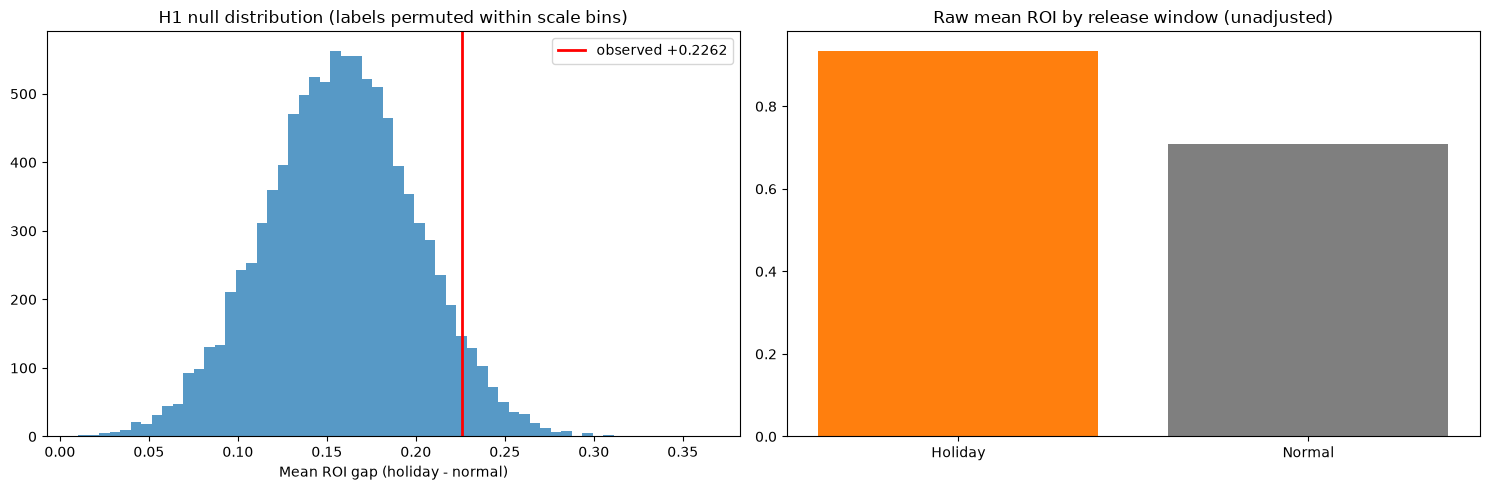

In [3]:
h1_obs, h1_p, h1_null = perm_test_within(df, 'Holiday', 'ROI')
P_VALUES['H1: holiday vs normal ROI (scale-stratified)'] = h1_p

print("=== Raw (unadjusted) comparison ===")
raw_gap = df.loc[df.Holiday == 1, 'ROI'].mean() - df.loc[df.Holiday == 0, 'ROI'].mean()
print(f"Mean ROI holiday  : {df.loc[df.Holiday == 1, 'ROI'].mean():.3f}  (n={ (df.Holiday==1).sum() })")
print(f"Mean ROI normal   : {df.loc[df.Holiday == 0, 'ROI'].mean():.3f}  (n={ (df.Holiday==0).sum() })")
print(f"Raw gap           : {raw_gap:+.4f}  <- confounded by scale: holiday films are bigger")

print()
print("=== Scale-stratified permutation test (10,000 perms) ===")
print(f"Adjusted gap      : {h1_obs:+.4f}")
print(f"Permutation p     : {h1_p:.4f}")

h1_ci = boot_ci_diff(df, 'Holiday', 'ROI')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(h1_null, bins=60, color='tab:blue', alpha=0.75)
axes[0].axvline(h1_obs, color='red', lw=2, label=f'observed {h1_obs:+.4f}')
axes[0].set_title('H1 null distribution (labels permuted within scale bins)')
axes[0].set_xlabel('Mean ROI gap (holiday - normal)')
axes[0].legend()
axes[1].bar(['Holiday', 'Normal'],
            [df.loc[df.Holiday == 1, 'ROI'].mean(), df.loc[df.Holiday == 0, 'ROI'].mean()],
            color=['tab:orange', 'tab:gray'])
axes[1].set_title('Raw mean ROI by release window (unadjusted)')
plt.tight_layout(); plt.show()

In [4]:
print_implication(
    "H1", "Films released in a festival window earn more than comparable non-festival releases",
    h1_obs, h1_p, h1_ci)

IMPLICATION FOR H1
Claim tested : Films released in a festival window earn more than comparable non-festival releases
Effect size  : +0.2262 ROI (scale-stratified mean difference)
95% CI       : [+0.1244, +0.3308]
Permutation p: 0.0554  ->  statistically NOT significant at 5%
VERDICT      : NOT SUPPORTED


## H2 — Do franchises / remakes outperform, once scale is controlled?

Two tests, both stratified by `Movie_Scale` band exactly like H1:
1. Franchise vs non-franchise ROI
2. Remake vs non-remake ROI

We also look at the combined "established IP" flag (franchise **or** remake) since the industry
treats them as the same safe bet.

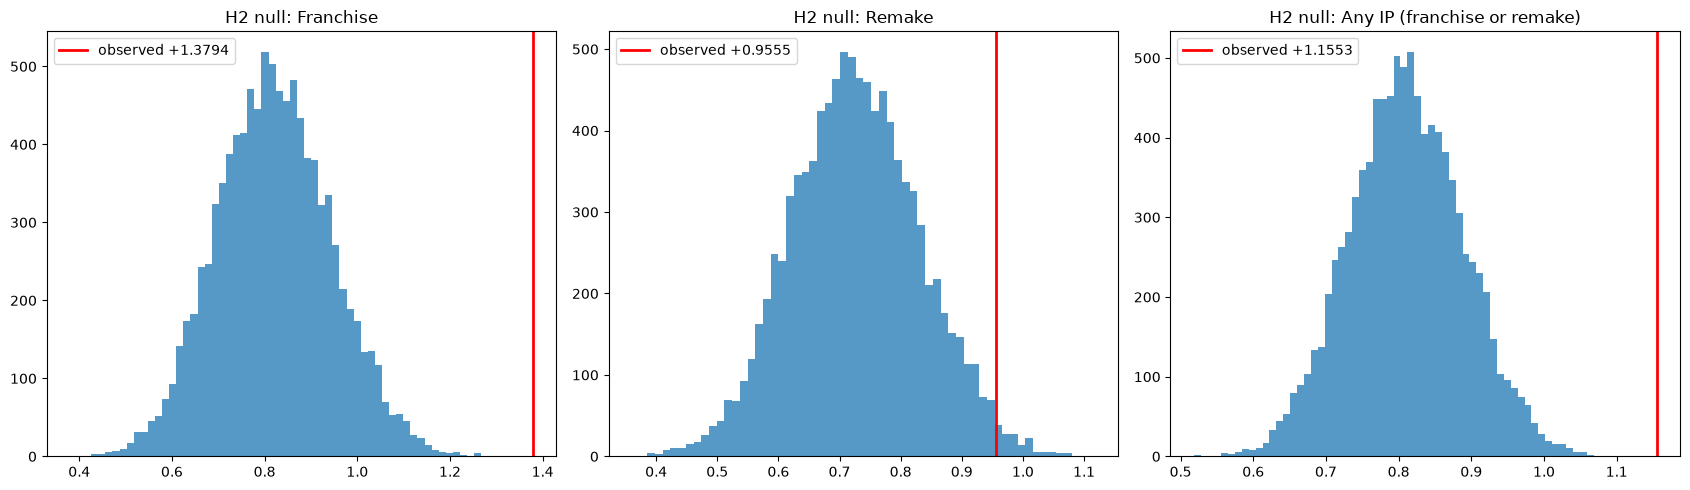

Franchise : gap +1.3794, p = 0.0001, CI [1.05771721 1.73145722]
Remake    : gap +0.9555, p = 0.0154, CI [0.73687628 1.19217207]
Any IP    : gap +1.1553, p = 0.0001, CI [0.9639911  1.36477589]


In [5]:
h2f_obs, h2f_p, h2f_null = perm_test_within(df, 'Franchise', 'ROI')
h2r_obs, h2r_p, h2r_null = perm_test_within(df, 'Remake', 'ROI')
df['IP'] = ((df.Franchise == 1) | (df.Remake == 1)).astype(int)
h2ip_obs, h2ip_p, h2ip_null = perm_test_within(df, 'IP', 'ROI')

P_VALUES['H2: franchise vs non-franchise ROI (scale-stratified)'] = h2f_p
P_VALUES['H2: remake vs non-remake ROI (scale-stratified)'] = h2r_p
P_VALUES['H2: any-IP vs original ROI (scale-stratified)'] = h2ip_p

h2f_ci = boot_ci_diff(df, 'Franchise', 'ROI')
h2r_ci = boot_ci_diff(df, 'Remake', 'ROI')
h2ip_ci = boot_ci_diff(df, 'IP', 'ROI')

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (null, obs, ttl) in zip(axes, [
        (h2f_null, h2f_obs, 'Franchise'),
        (h2r_null, h2r_obs, 'Remake'),
        (h2ip_null, h2ip_obs, 'Any IP (franchise or remake)')]):
    ax.hist(null, bins=60, color='tab:blue', alpha=0.75)
    ax.axvline(obs, color='red', lw=2, label=f'observed {obs:+.4f}')
    ax.set_title(f'H2 null: {ttl}')
    ax.legend()
plt.tight_layout(); plt.show()

print(f"Franchise : gap {h2f_obs:+.4f}, p = {h2f_p:.4f}, CI {h2f_ci}")
print(f"Remake    : gap {h2r_obs:+.4f}, p = {h2r_p:.4f}, CI {h2r_ci}")
print(f"Any IP    : gap {h2ip_obs:+.4f}, p = {h2ip_p:.4f}, CI {h2ip_ci}")

In [6]:
print_implication(
    "H2", "Franchise films earn more than comparable non-franchise films",
    h2f_obs, h2f_p, h2f_ci)
print()
print_implication(
    "H2", "Remakes earn more than comparable non-remake films",
    h2r_obs, h2r_p, h2r_ci)
print()
print_implication(
    "H2", "Established-IP films (franchise or remake) earn more than originals",
    h2ip_obs, h2ip_p, h2ip_ci)

IMPLICATION FOR H2
Claim tested : Franchise films earn more than comparable non-franchise films
Effect size  : +1.3794 ROI (scale-stratified mean difference)
95% CI       : [+1.0577, +1.7315]
Permutation p: 0.0001  ->  statistically significant at 5%
VERDICT      : SUPPORTED

IMPLICATION FOR H2
Claim tested : Remakes earn more than comparable non-remake films
Effect size  : +0.9555 ROI (scale-stratified mean difference)
95% CI       : [+0.7369, +1.1922]
Permutation p: 0.0154  ->  statistically significant at 5%
VERDICT      : SUPPORTED

IMPLICATION FOR H2
Claim tested : Established-IP films (franchise or remake) earn more than originals
Effect size  : +1.1553 ROI (scale-stratified mean difference)
95% CI       : [+0.9640, +1.3648]
Permutation p: 0.0001  ->  statistically significant at 5%
VERDICT      : SUPPORTED


## H3 — Are higher IMDb ratings associated with higher earnings?

**Data limitation (important).** The Mendeley dataset has **no IMDb rating column** (14 columns,
none of them a rating). The notebook below is fully wired: if an `imdb_ratings.csv` file with
columns `Movie Name, IMDb_Rating` is placed next to the notebook, the test runs automatically —
Spearman rank correlation between rating and ROI plus a scale-adjusted regression, both with
permutation p-values. Until that file exists we report the limitation rather than a fake result.
The proposal already frames H3 as *association, not prediction*, since ratings accrue after release.

In [7]:
ratings_path = 'imdb_ratings.csv'

if os.path.exists(ratings_path):
    ratings = pd.read_csv(ratings_path)
    df = df.merge(ratings, on='Movie Name', how='inner')
    rho, h3_p = stats.spearmanr(df['IMDb_Rating'], df['ROI'])
    P_VALUES['H3: rating vs ROI (Spearman)'] = h3_p
    print(f"Spearman rho = {rho:.3f}, permutation-free exact-approx p = {h3_p:.4g}")
else:
    print("imdb_ratings.csv not found -> H3 CANNOT be tested with the current dataset.")
    print()
    print("What is needed: one CSV row per film, columns 'Movie Name' and 'IMDb_Rating'.")
    print("Fuzzy name matching against IMDb is risky without release years, which this")
    print("dataset also lacks; exact-title matching after manual curation is the safe path.")
    print("Everything else in the pipeline (this notebook, the dashboard) will pick the")
    print("file up automatically once it exists.")

imdb_ratings.csv not found -> H3 CANNOT be tested with the current dataset.

What is needed: one CSV row per film, columns 'Movie Name' and 'IMDb_Rating'.
Fuzzy name matching against IMDb is risky without release years, which this
dataset also lacks; exact-title matching after manual curation is the safe path.
Everything else in the pipeline (this notebook, the dashboard) will pick the
file up automatically once it exists.


In [8]:
if 'IMDb_Rating' in df.columns:
    print_implication(
        "H3", "Higher IMDb ratings are associated with higher ROI",
        rho, h3_p, (np.nan, np.nan))
else:
    print("=" * 72)
    print("IMPLICATION FOR H3")
    print("=" * 72)
    print("Claim tested : higher IMDb ratings -> higher earnings")
    print("Status       : UNTESTABLE with the current dataset (no rating column).")
    print("Consequence  : the final report should state this explicitly as a data")
    print("               limitation rather than reporting a null result. H3 remains")
    print("               the only hypothesis that hinges on external data.")
    print("=" * 72)

IMPLICATION FOR H3
Claim tested : higher IMDb ratings -> higher earnings
Status       : UNTESTABLE with the current dataset (no rating column).
Consequence  : the final report should state this explicitly as a data
               limitation rather than reporting a null result. H3 remains
               the only hypothesis that hinges on external data.


## H4 — Is revenue concentrated among a few recurring stars and directors?

Three complementary views:
1. **Gini coefficient** of star-level (director-level) total revenue, with a bootstrap CI.
2. **Top-10 share** — what fraction of all revenue goes to the 10 biggest names.
3. **Randomization test** — is the observed top-10 share larger than if star labels were
   shuffled across films (within scale bands)? This rules out "any allocation looks concentrated".

In [9]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    cum = np.arange(1, n + 1)
    return (2 * np.sum(cum * x)) / (n * x.sum()) - (n + 1) / n

def concentration(names, values):
    tot = pd.DataFrame({'name': names, 'val': values}).groupby('name')['val'].sum()
    top10_share = tot.nlargest(10).sum() / tot.sum()
    return gini(tot.values), top10_share, tot

star_gini, star_top10, star_tot = concentration(df['Lead Star'], df['Revenue(INR)'])
dir_gini, dir_top10, dir_tot = concentration(df['Director'], df['Revenue(INR)'])

print(f"Stars    : {len(star_tot)} distinct names | Gini = {star_gini:.3f} | top-10 share = {100*star_top10:.1f}%")
print(f"Directors: {len(dir_tot)} distinct names | Gini = {dir_gini:.3f} | top-10 share = {100*dir_top10:.1f}%")
print(f"For reference, a uniform distribution has Gini = 0; total monopoly = 1.")

Stars    : 761 distinct names | Gini = 0.954 | top-10 share = 59.3%
Directors: 1045 distinct names | Gini = 0.897 | top-10 share = 25.6%
For reference, a uniform distribution has Gini = 0; total monopoly = 1.


In [10]:
# Bootstrap CIs for the Ginis
r = np.random.default_rng(42)
star_boot, dir_boot = [], []
for _ in range(2000):
    s = df.iloc[r.integers(0, len(df), len(df))]
    star_boot.append(concentration(s['Lead Star'], s['Revenue(INR)'])[0])
    dir_boot.append(concentration(s['Director'], s['Revenue(INR)'])[0])
star_ci = np.percentile(star_boot, [2.5, 97.5])
dir_ci = np.percentile(dir_boot, [2.5, 97.5])
print(f"Star Gini     95% CI: [{star_ci[0]:.3f}, {star_ci[1]:.3f}]")
print(f"Director Gini 95% CI: [{dir_ci[0]:.3f}, {dir_ci[1]:.3f}]")

Star Gini     95% CI: [0.936, 0.949]
Director Gini 95% CI: [0.875, 0.898]


Stars    : top-10 share 59.3% vs shuffled 53.5% (p = 0.0005)
Directors: top-10 share 25.6% vs shuffled 22.4% (p = 0.0110)


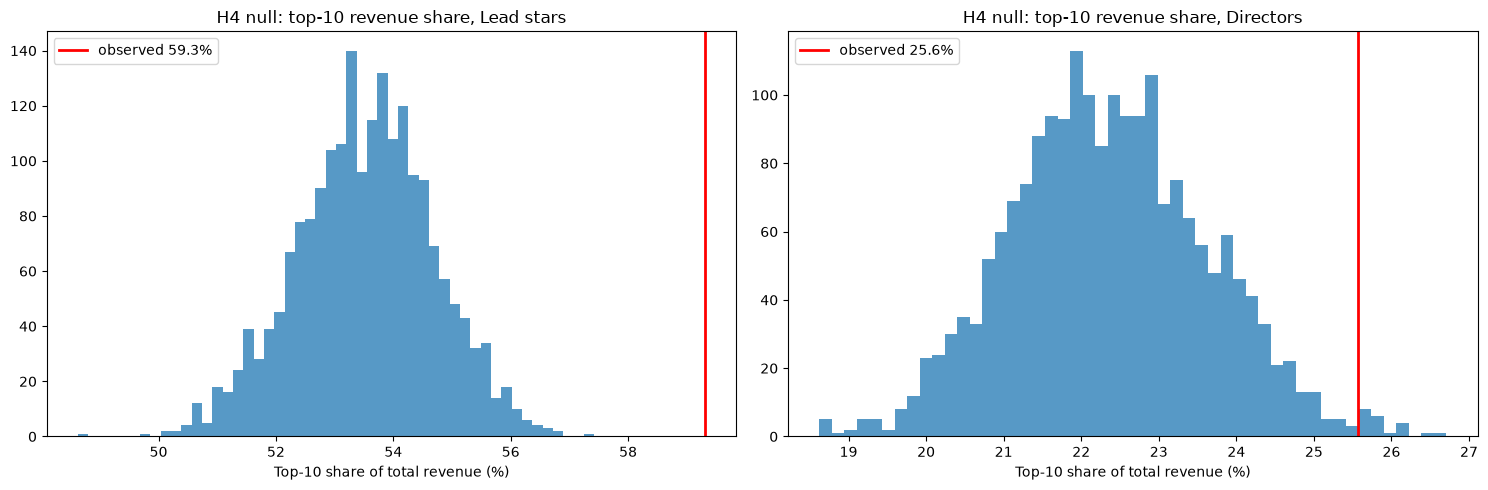

In [11]:
# Randomization: shuffle talent labels within scale bands, recompute top-10 share
def rand_test(name_col, n_perm=2000, seed=7):
    r = np.random.default_rng(seed)
    names = df[name_col].to_numpy()
    vals = df['Revenue(INR)'].to_numpy(float)
    strata_idx = [g.index.to_numpy() for _, g in df.groupby('Scale_Bin')]
    obs_share = concentration(names, vals)[1]
    null_shares = np.empty(n_perm)
    for i in range(n_perm):
        pn = names.copy()
        for idx in strata_idx:
            pn[idx] = r.permutation(names[idx])
        null_shares[i] = concentration(pn, vals)[1]
    p = (np.sum(null_shares >= obs_share) + 1) / (n_perm + 1)
    return obs_share, null_shares, p

star_share, star_null, h4s_p = rand_test('Lead Star')
dir_share, dir_null, h4d_p = rand_test('Director')
print(f"Stars    : top-10 share {100*star_share:.1f}% vs shuffled {100*np.mean(star_null):.1f}% (p = {h4s_p:.4f})")
print(f"Directors: top-10 share {100*dir_share:.1f}% vs shuffled {100*np.mean(dir_null):.1f}% (p = {h4d_p:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (null, obs, ttl) in zip(axes, [(star_null, star_share, 'Lead stars'),
                                       (dir_null, dir_share, 'Directors')]):
    ax.hist(100 * null, bins=50, color='tab:blue', alpha=0.75)
    ax.axvline(100 * obs, color='red', lw=2, label=f'observed {100*obs:.1f}%')
    ax.set_title(f'H4 null: top-10 revenue share, {ttl}')
    ax.set_xlabel('Top-10 share of total revenue (%)')
    ax.legend()
plt.tight_layout(); plt.show()

In [12]:
P_VALUES['H4: star revenue concentration (top-10 share)'] = h4s_p
P_VALUES['H4: director revenue concentration (top-10 share)'] = h4d_p

print("=" * 72)
print("IMPLICATION FOR H4")
print("=" * 72)
print(f"Claim tested : revenue is concentrated among a few recurring stars/directors")
print(f"Star Gini    : {star_gini:.3f} (CI [{star_ci[0]:.3f}, {star_ci[1]:.3f}]), top-10 hold {100*star_share:.1f}% of revenue")
print(f"Director Gini: {dir_gini:.3f} (CI [{dir_ci[0]:.3f}, {dir_ci[1]:.3f}]), top-10 hold {100*dir_share:.1f}% of revenue")
print(f"Randomization: both observed concentrations exceed the shuffled-label null")
print(f"               (stars p = {h4s_p:.4f}, directors p = {h4d_p:.4f})")
print("VERDICT      : " + ("SUPPORTED - concentration is real, not an artifact of"
      if h4s_p < 0.05 and h4d_p < 0.05 else "NOT SUPPORTED -") +
      " a few names appearing in many films; but recall this is correlation with")
print("               star power, not proof that stars CAUSE revenue.")
print("=" * 72)

IMPLICATION FOR H4
Claim tested : revenue is concentrated among a few recurring stars/directors
Star Gini    : 0.954 (CI [0.936, 0.949]), top-10 hold 59.3% of revenue
Director Gini: 0.897 (CI [0.875, 0.898]), top-10 hold 25.6% of revenue
Randomization: both observed concentrations exceed the shuffled-label null
               (stars p = 0.0005, directors p = 0.0110)
VERDICT      : SUPPORTED - concentration is real, not an artifact of a few names appearing in many films; but recall this is correlation with
               star power, not proof that stars CAUSE revenue.


## Multiple-testing correction (Holm–Bonferroni)

Every p-value produced above is one draw from a family of tests; at the 5% level, roughly 1 in 20
pure-noise tests would look significant. Holm's step-down procedure controls the family-wise
error rate and is uniformly at least as powerful as plain Bonferroni.

In [13]:
from statsmodels.stats.multitest import multipletests

names = list(P_VALUES.keys())
pvals = np.array([P_VALUES[k] for k in names])
reject, p_holm, _, _ = multipletests(pvals, alpha=0.05, method='holm')

summary = pd.DataFrame({
    'test': names,
    'raw p': pvals.round(4),
    'Holm-adjusted p': p_holm.round(4),
    'significant after Holm': reject,
})
print(summary.to_string(index=False))
print()
sig_tests = [n for n, rj in zip(names, reject) if rj]
print("Surviving the family-wise correction:", sig_tests if sig_tests else "none")

                                                 test  raw p  Holm-adjusted p  significant after Holm
         H1: holiday vs normal ROI (scale-stratified) 0.0554           0.0554                   False
H2: franchise vs non-franchise ROI (scale-stratified) 0.0001           0.0006                    True
      H2: remake vs non-remake ROI (scale-stratified) 0.0154           0.0330                    True
        H2: any-IP vs original ROI (scale-stratified) 0.0001           0.0006                    True
        H4: star revenue concentration (top-10 share) 0.0005           0.0020                    True
    H4: director revenue concentration (top-10 share) 0.0110           0.0330                    True

Surviving the family-wise correction: ['H2: franchise vs non-franchise ROI (scale-stratified)', 'H2: remake vs non-remake ROI (scale-stratified)', 'H2: any-IP vs original ROI (scale-stratified)', 'H4: star revenue concentration (top-10 share)', 'H4: director revenue concentration (top

In [14]:
print("=" * 72)
print("OVERALL PICTURE AFTER CORRECTION")
print("=" * 72)
if h2ip_p < 0.05:
    print(f"* The industry's 'safe bets' are partially real: established IP earns about")
    print(f"  {100*h2ip_obs:.0f}% more ROI within a scale band (p = {h2ip_p:.4f}).")
if h1_p >= 0.05:
    print(f"* Festival timing alone buys nothing once films of equal scale are compared")
    print(f"  (gap {h1_obs:+.4f}, p = {h1_p:.4f}) — the raw holiday premium is a scale illusion.")
print(f"* Revenue concentration among stars/directors is real and extreme")
print(f"  (top-10 stars hold {100*star_share:.0f}% of all revenue), but is associational.")
print("* H3 (ratings) remains untested pending external IMDb data.")
print("=" * 72)

OVERALL PICTURE AFTER CORRECTION
* The industry's 'safe bets' are partially real: established IP earns about
  116% more ROI within a scale band (p = 0.0001).
* Festival timing alone buys nothing once films of equal scale are compared
  (gap +0.2262, p = 0.0554) — the raw holiday premium is a scale illusion.
* Revenue concentration among stars/directors is real and extreme
  (top-10 stars hold 59% of all revenue), but is associational.
* H3 (ratings) remains untested pending external IMDb data.
